# Laboratorio Semana 12 — GeoPandas y Datos Espaciales en el Perú


**Integrantes (Data Hunters):** Fernando Torres, Romy Tipacti, Arturo Alvarez    
**Entrega:** Pre-Hito 3 — Tarea 4




In [1]:
# Importamos las librerías necesarias para el análisis geoespacial
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 6)
pd.set_option("display.max_columns", 30)


## 1. Carga de los shapefiles administrativos del Perú

Cargamos las capas de regiones, provincias y distritos del Instituto Geográfico Nacional (IGN) almacenadas en la carpeta `peru_shapes/`.


In [2]:
# Rutas relativas a los shapefiles
ruta_base = "peru_shapes" if os.path.exists("peru_shapes") else "Entrega_3/peru_shapes"

ruta_adm1 = os.path.join(ruta_base, "per_admbnda_adm1_ign_20200714.shp")   # Regiones
ruta_adm2 = os.path.join(ruta_base, "per_admbnda_adm2_ign_20200714.shp")   # Provincias
ruta_adm3 = os.path.join(ruta_base, "per_admbnda_adm3_ign_20200714.shp")   # Distritos

# Leemos las capas con GeoPandas
regiones   = gpd.read_file(ruta_adm1)
provincias = gpd.read_file(ruta_adm2)
distritos  = gpd.read_file(ruta_adm3)

print("Regiones cargadas   :", len(regiones))
print("Provincias cargadas :", len(provincias))
print("Distritos cargados  :", len(distritos))
print("Sistema de referencia de coordenadas (CRS):", regiones.crs)


Regiones cargadas   : 25
Provincias cargadas : 196
Distritos cargados  : 1873
Sistema de referencia de coordenadas (CRS): EPSG:4326


# <font color=blue>DESAFÍO</font>

## <font color=green>B. Una región de interés</font>

Revisando nuestra matriz analítica de proyectos de inversión pública, después de Lima, **Cusco** es la región que concentra la mayor cantidad de proyectos en ejecución (289 obras). Por ello, seleccionamos **Cusco** como nuestra región de interés para el análisis espacial:

1. Mostramos sus 13 provincias y las representamos en el mapa con sus nombres.
2. Seleccionamos la provincia de **Cusco**.
3. Mostramos los distritos de esa provincia y los visualizamos en el mapa.


Número de provincias en la región Cusco: 13


,ADM2_ES,ADM2_PCODE
0,Acomayo,PE0802
1,Anta,PE0803
2,Calca,PE0804
3,Canas,PE0805
4,Canchis,PE0806
5,Chumbivilcas,PE0807
6,Cusco,PE0801
7,Espinar,PE0808
8,La Convencion,PE0809
9,Paruro,PE0810


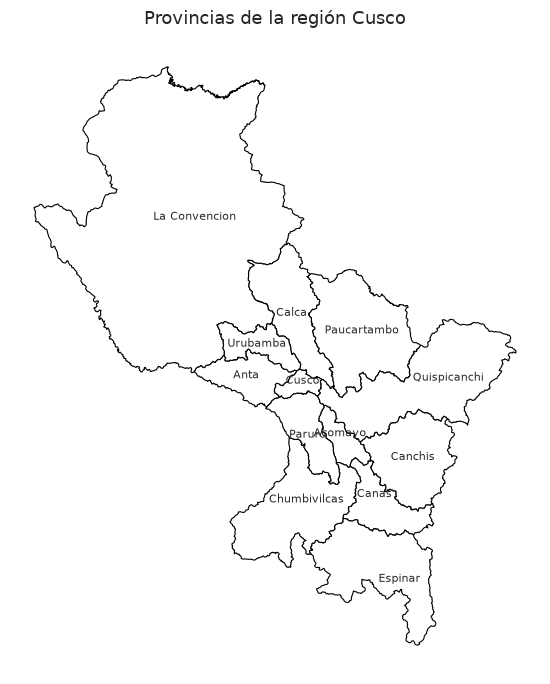

In [3]:
# 1. Filtramos las provincias pertenecientes a la región Cusco
provincias_cusco = provincias[provincias["ADM1_ES"] == "Cusco"].copy()

print(f"Número de provincias en la región Cusco: {len(provincias_cusco)}")

# Mostramos la lista ordenada de provincias con sus códigos
display(
    provincias_cusco[["ADM2_ES", "ADM2_PCODE"]]
    .sort_values("ADM2_ES")
    .reset_index(drop=True)
)

# Graficamos las provincias de Cusco con sus nombres anotados
ax = provincias_cusco.plot(
    figsize=(9, 7),
    facecolor="white",
    edgecolor="black",
    linewidth=0.8
)

# Anotamos el nombre de cada provincia en su punto representativo
for idx, row in provincias_cusco.iterrows():
    coords = row["geometry"].representative_point().coords[0]
    ax.annotate(
        text=row["ADM2_ES"],
        xy=coords,
        horizontalalignment="center",
        fontsize=8,
        color="#2b2b2b"
    )

ax.set_title("Provincias de la región Cusco", fontsize=13, pad=10)
ax.set_axis_off()
plt.tight_layout()
plt.show()


Número de distritos en la provincia de Cusco: 8


,ADM3_ES,ADM3_PCODE
0,Ccorca,PE080102
1,Cusco,PE080101
2,Poroy,PE080103
3,San Jeronimo,PE080104
4,San Sebastian,PE080105
5,Santiago,PE080106
6,Saylla,PE080107
7,Wanchaq,PE080108


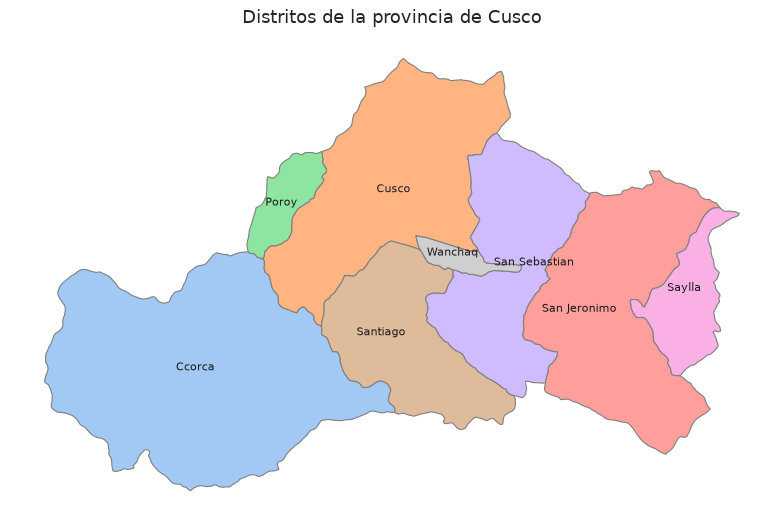

In [4]:
# 2. Seleccionamos la provincia de Cusco y filtramos sus distritos
distritos_prov_cusco = distritos[
    (distritos["ADM1_ES"] == "Cusco") &
    (distritos["ADM2_ES"] == "Cusco")
].copy()

print(f"Número de distritos en la provincia de Cusco: {len(distritos_prov_cusco)}")

# 3. Mostramos la lista ordenada de los distritos
display(
    distritos_prov_cusco[["ADM3_ES", "ADM3_PCODE"]]
    .sort_values("ADM3_ES")
    .reset_index(drop=True)
)

# Graficamos los distritos con la paleta pastel y sus nombres
colores = sns.color_palette("pastel", len(distritos_prov_cusco))

ax = distritos_prov_cusco.plot(
    figsize=(8, 7),
    color=colores,
    edgecolor="gray",
    linewidth=0.8
)

for idx, row in distritos_prov_cusco.iterrows():
    coords = row["geometry"].representative_point().coords[0]
    ax.annotate(
        text=row["ADM3_ES"],
        xy=coords,
        horizontalalignment="center",
        fontsize=8,
        color="#1a1a1a"
    )

ax.set_title("Distritos de la provincia de Cusco", fontsize=13, pad=10)
ax.set_axis_off()
plt.tight_layout()
plt.show()


## <font color=green>C. Proyecto (Componente espacial de nuestra base)</font>

En base a la matriz analítica de nuestro proyecto:

- **Nivel geográfico:** Utilizamos el nivel **departamental / regional**, que está registrado en el atributo `departamento` para cada proyecto de inversión pública (CUI).
- **Columna de enlace con shapefile:** La columna `departamento` de nuestra matriz analítica se vincula directamente con el atributo `ADM1_ES` de la capa `regiones` del shapefile oficial (homologando mayúsculas y nombres sin tildes).
- **Uso de la ubicación:** La ubicación se utiliza para **visualizar resultados y contextualizar el perfilamiento** (por ejemplo, analizar la distribución espacial de los clusters encontrados o la concentración de proyectos con alerta de gasto adelantado). No se incluyó como variable continua de distancia en el clustering para evitar que la cercanía geográfica sesgue artificialmente los grupos basados en ejecución y presupuesto.


Top 10 departamentos con mayor cantidad de proyectos:


,ADM1_ES,n_proyectos
0,Lima,565
1,Cusco,289
2,Arequipa,133
3,Puno,113
4,Ayacucho,104
5,Ancash,98
6,Junin,79
7,Apurimac,79
8,Cajamarca,70
9,Amazonas,62


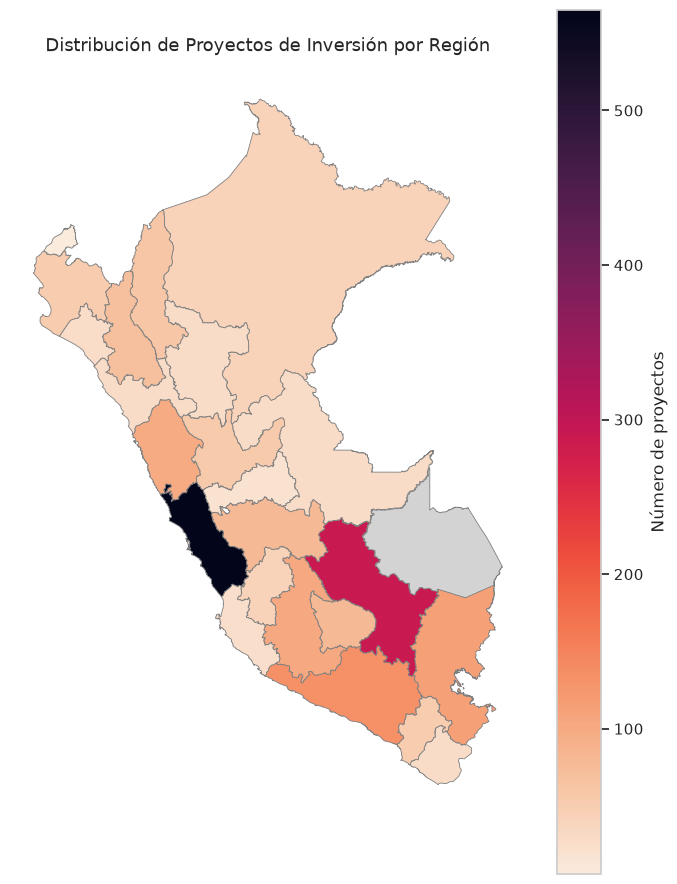

In [ ]:
# Cargamos la matriz analítica del proyecto
ruta_datos = "matriz_analitica_con_clusters.csv" if os.path.exists("matriz_analitica_con_clusters.csv") else "Entrega_3/matriz_analitica_con_clusters.csv"
df_proyecto = pd.read_csv(ruta_datos)

# Contamos la cantidad de proyectos por departamento y adecuamos el nombre al shapefile
conteo_dep = (
    df_proyecto["departamento"]
    .str.strip()
    .str.title()
    .replace({"Provincia Constitucional Del Callao": "Callao"})
    .value_counts()
    .reset_index()
)
conteo_dep.columns = ["ADM1_ES", "n_proyectos"]
conteo_dep = conteo_dep[conteo_dep["ADM1_ES"] != ""]

print("Top 10 departamentos con mayor cantidad de proyectos:")
display(conteo_dep.head(10))

# Unimos la tabla de proyectos con el GeoDataFrame de regiones (merge hacia la izquierda)
mapa_proyectos = regiones.merge(
    conteo_dep,
    on="ADM1_ES",
    how="left"
)

# Graficamos el mapa coroplético de distribución territorial de proyectos
ax = mapa_proyectos.plot(
    column="n_proyectos",
    cmap="rocket_r",
    figsize=(7, 9),
    edgecolor="gray",
    linewidth=0.6,
    legend=True,
    legend_kwds={"label": "Número de proyectos"},
    missing_kwds={"color": "lightgray"}
)

ax.set_title("Distribución de Proyectos de Inversión por Región", fontsize=13, pad=10)
ax.set_axis_off()
plt.tight_layout()
plt.show()


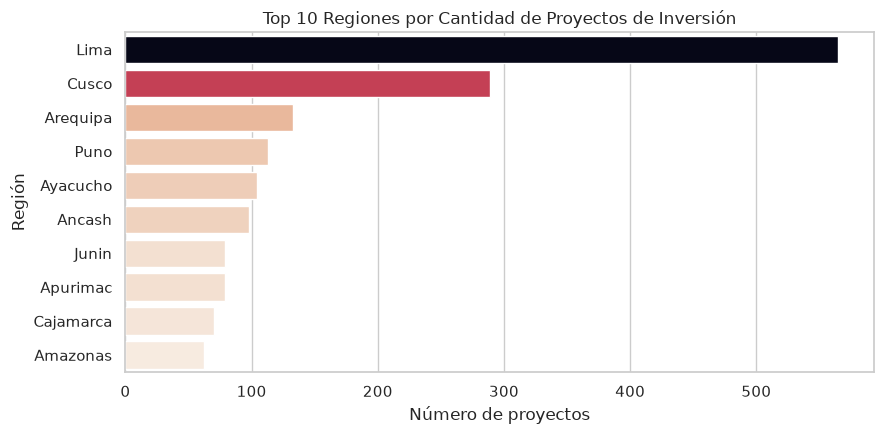

In [6]:
# Gráfico de barras con los 10 departamentos con más proyectos (Seaborn)
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(
    data=conteo_dep.head(10),
    x="n_proyectos",
    y="ADM1_ES",
    hue="n_proyectos",
    palette="rocket_r",
    legend=False
)
ax.set_title("Top 10 Regiones por Cantidad de Proyectos de Inversión", fontsize=12)
ax.set_xlabel("Número de proyectos")
ax.set_ylabel("Región")
plt.tight_layout()
plt.show()
